## 1、什么是 RAG

RAG（Retrieval-Augmented Generation）是一种结合了 **信息检索（Retrieval）** 和 **文本生成（Generation）** 的AI技术框架。

核心思想：在生成文本时，不仅依赖于模型本身的参数，还可以从外部知识库检索相关信息，以增强生成的内容。

RAG 优势：

   * 动态更新知识：相比于依赖纯粹的 LLM 训练后的参数，RAG 可以从外部知识库获取最新信息，无需重新训练模型。

   * 提高生成质量：减少 LLM 幻觉，使得生成内容更加精准和可解释。

   * 本地数据的隐私性：很多企业数据不能上传云端，或者模型训练。

应用场景：RAG 适合用于各种需要获取动态知识的 NLP 任务，包括但不局限于

   * 智能问答：结合企业文档库，实现精准的企业内部问答系统

   * 法律和医学咨询：结合法律法规、医学文献，提供更可靠的专业问答

   * 代码生成与修复：结合代码文档、技术文档，增强代码生成的准确性和规范性

## 2、RAG 的工作原理

RAG 主要包括两个阶段：

   * 检索（Retrieval）：从知识库（如文档、数据库、网络等）中检索出与输入问题最相关的内容。
   * 生成（Generation）：利用检索到的信息作为额外的上下文输入，引导大语言模型生成更准确、更可靠的内容。

   内容生成流程大致为：用户输入要询问的内容 
                        -> 通过向量数据库（如 FAISS、ChromaDB、Milvus）检索相关内容 
                        -> 将检索到的内容作为上下文，输入给 LLM 
                        -> 生成增强后的内容。

向量相似度原理：

   * 相似单词在向量空间中的距离更近

   * 余弦相似度cos越接近1，语义越相似。即向量间角度越小，相似度越高

   * 不同语义类别形成独立聚类

   在 RAG 中，余弦相似度的 1、0、-1，可以理解为两个文本经过 Embedding 后，在向量空间中的方向关系。
   | 余弦相似度 | 数学含义 | RAG 中的理解 |
   | --- | --- | --- |
   | 1 | 方向完全相同（0°） | 两个文本向量方向完全一致，语义匹配程度通常很高 |
   | 0 | 相互正交（90°） | 两个文本向量没有方向上的相似性，不表示语义绝对无关 |
   | -1 | 方向完全相反（180°） | 两个文本向量方向完全相反，不等于文本语义相反 |
   
 
 ## 3、RAG 核心技术框架

 ![完整 RAG 技术架构图.png](<attachment:完整 RAG 技术架构图.png>)

 ## 4、RAG 8 个核心技术组件

   | 核心组件 | 中文名称 | 主要作用 |
   | --- | --- | --- |
   | 1. Document Loader | 文档加载器 | 读取 PDF、Word、数据库等数据 |
   | 2. Text Splitter | 文本切分器 | 将长文档切分成多个 Chunk |
   | 3. Embedding Model | 向量化模型 | 将文本转换成高维向量 |
   | 4. Vector Store | 向量存储 | 存储向量并建立检索索引 |
   | 5. Retriever | 检索器 | 根据问题召回相关文档 |
   | 6. Reranker | 重排序器 | 对检索结果重新排序，提高相关性 |
   | 7. Prompt Template | 提示词模板 | 将问题与检索内容组织成 LLM 输入 |
   | 8. LLM | 大语言模型 | 根据检索内容生成最终回答 |

   完整的 RAG 技术流程（8组件）

   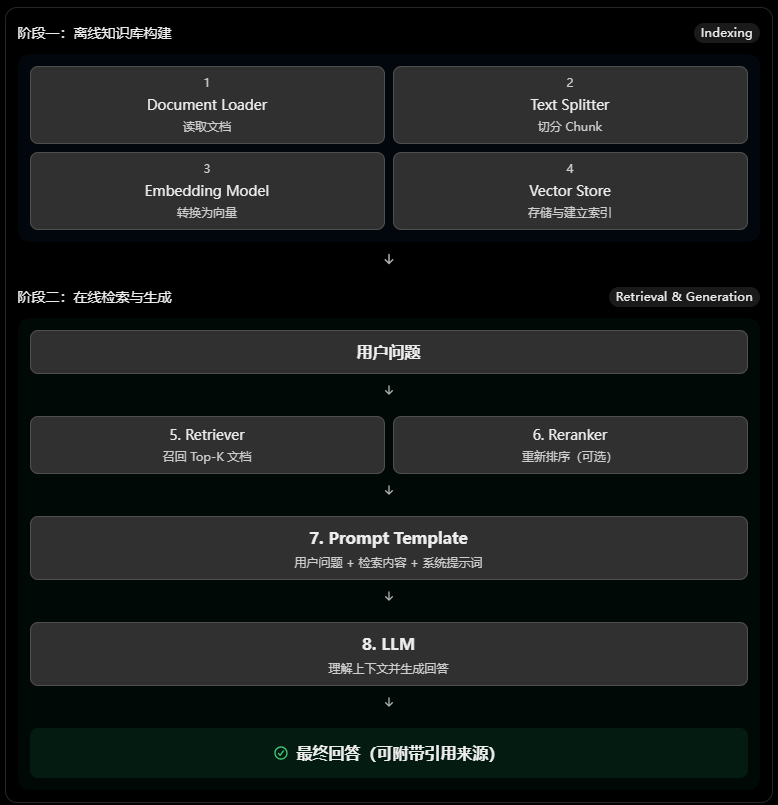
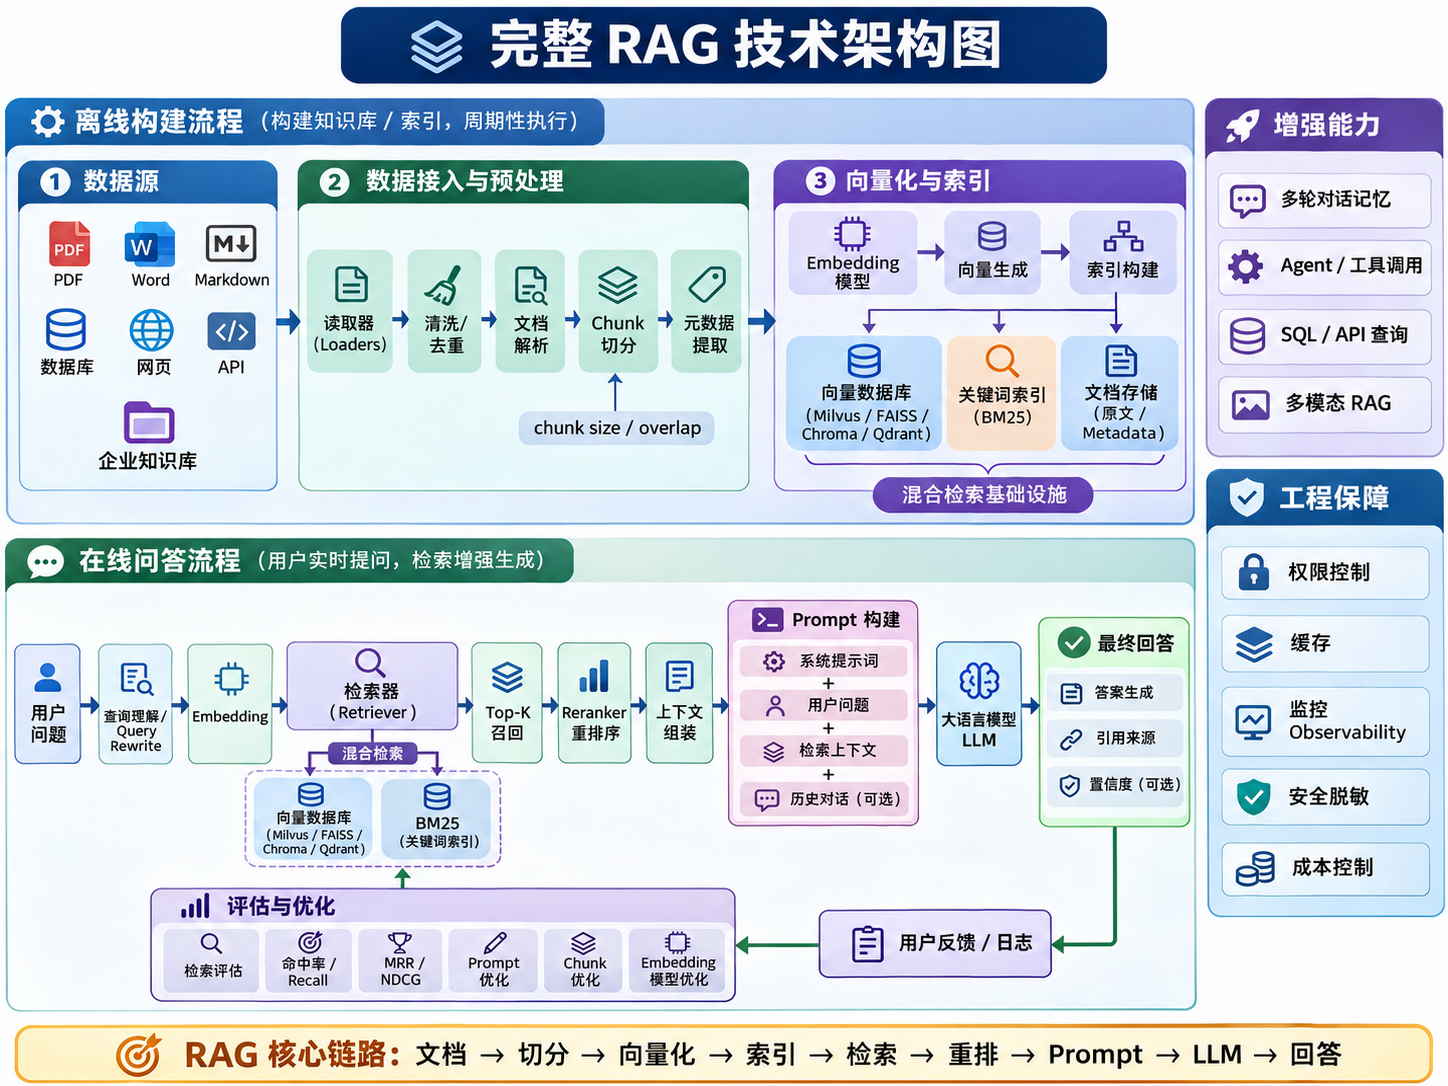

## LlamaIndex

### 1、介绍

LlamaIndex 是一个用于 LLM 应用程序的数据框架，用于注入、结构化，并访问私有或特定领域数据。

LlamaIndex 最初叫 GPT Index，它的核心价值和使命：让私有数据高效接入 LLM。整个设计都围绕 `数据接入 -> 索引构建 -> 查询检索` 这条主线展开。

所以，这个框架非常适合做 RAG。

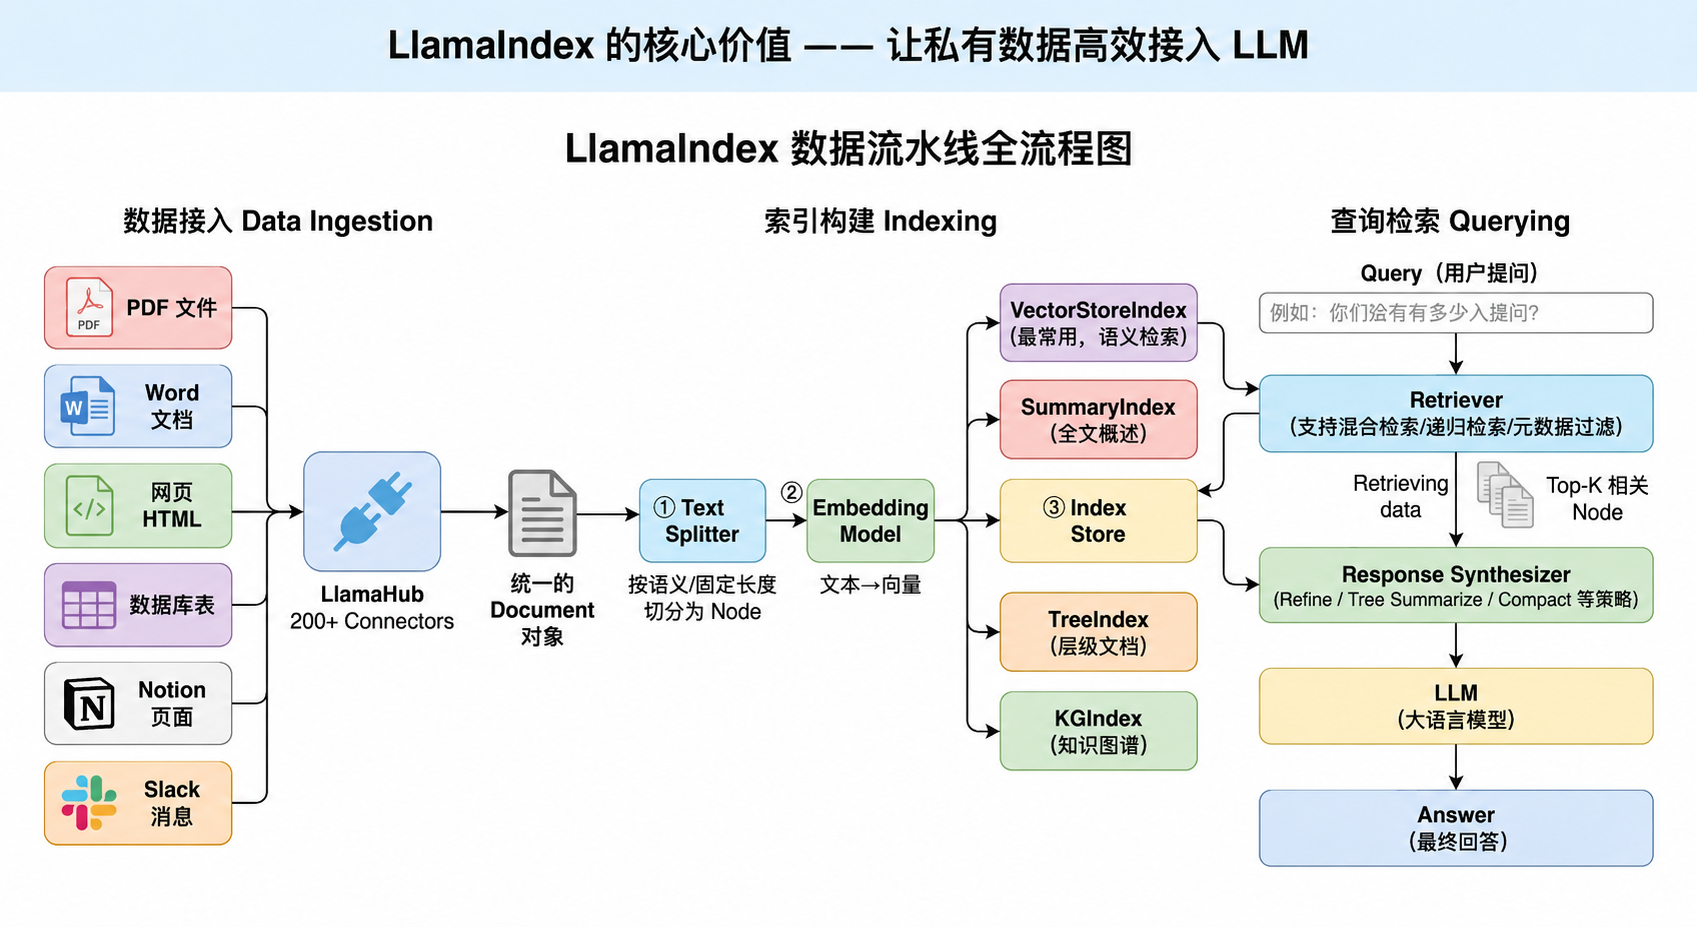

阶段1 数据接入（Data Ingestion）

LlamaIndex 提供了丰富的数据连接器（Data Connector），也叫 Reader，可以从各种数据源（PDF、Word、HTML、Markdown、API、数据库等）加载数据。

LlamaHub 社区提供了大量开箱即用的 Reader。加载进来的数据通常会被统一抽象为 `Document` 对象，便于后续处理。

阶段2 索引构建（Indexing）

`Document` 对象首先经过文本分割（Chunking），被切分为多个 `Node`（文本片段），然后根据索引类型进行向量化（Embedding）等处理，最终构建索引。

LlamaIndex 支持多种索引类型：

- **VectorStoreIndex（向量索引）**：最常用，通过 Embedding 将文本转换为向量，支持语义相似度检索。
- **SummaryIndex（摘要索引）**：按顺序组织 Node，适合全文遍历、概览等场景。
- **TreeIndex（树状索引）**：以树状结构组织文本，适合层级化检索与汇总。
- **KnowledgeGraphIndex（知识图谱索引）**：通过实体及其关系组织知识，适合关系查询（新版本可关注 PropertyGraphIndex）。

不同索引类型对应不同的数据组织方式和检索策略，这是 LlamaIndex 的重要特色之一。

阶段3 查询检索（Querying）

这是用户实际使用的环节。LlamaIndex 提供了查询引擎（QueryEngine）来处理用户的问题，主要流程如下：

1. **Retriever（检索器）**：根据用户问题，从索引中检索最相关的 Node（例如 Top-K 个文本片段）。
2. **Response Synthesizer（响应合成器）**：将检索到的 Node 与用户问题组织起来，调用 LLM 生成回答，可采用 Refine、Compact、Tree Summarize 等策略。
3. **LLM（大语言模型）**：结合检索到的上下文生成最终回答（Answer）。

通过这一流程，LLM 可以利用外部私有数据回答问题，而不需要重新训练模型。


In [ ]:

"""
LlamaIndex PDF RAG 入门示例（DeepSeek + 本地 BGE Embedding）

LlamaIndex 是组件化的数据索引与检索框架，主要使用流程：

    1. 全局配置（Settings）
       配置 LLM、Embedding 模型、文本切分器等默认组件。

    2. 数据接入（Reader）
       从 PDF 等数据源加载数据，转换为 Document 对象。

    3. 索引构建（Index）
       Document → Chunking → Node → Embedding → VectorStoreIndex
       将文档切分为 Node，计算向量并构建索引。

    4. 创建查询引擎（QueryEngine）
       组合 Retriever（检索器）和 Response Synthesizer（响应合成器）。

    5. 执行查询（Query）
       Question → Embedding → Retriever → Top-K Nodes → LLM → Answer

核心特点：
    - Settings 提供全局默认配置，也支持局部传参覆盖。
    - Index 负责组织和索引数据，Retriever 负责检索相关内容。
    - QueryEngine 封装检索和 LLM 回答生成过程。
    - 本示例采用内存向量存储，每次运行都会重新构建索引。
"""

import os

PROJECT_ROOT = "/home/huyuanhai/project/ai"

# 在导入 Hugging Face 相关库前配置镜像地址，解决模型下载困难的问题。
os.environ.setdefault("HF_ENDPOINT", "https://hf-mirror.com")

# 指定 NLTK 数据目录，避免默认目录存在共享写入权限问题。
os.environ.setdefault(
    "NLTK_DATA",
    PROJECT_ROOT + "/.cache/nltk_data",
)

# 模型配置
LLM_DEEPSEEK_API_KEY = os.environ.get("DEEPSEEK_API_KEY")
LLM_DEEPSEEK_BASE_URL = "https://api.deepseek.com"
LLM_MODEL_NAME = "deepseek-flash"
EMBEDDING_MODEL_NAME = "BAAI/bge-small-zh-v1.5"

from llama_index.core import Settings, VectorStoreIndex, SimpleDirectoryReader
from llama_index.core.node_parser import SentenceSplitter
from llama_index.llms.openai_like import OpenAILike
from llama_index.embeddings.huggingface import HuggingFaceEmbedding


# ==================== 1. 全局配置（Settings） ====================

# LLM：使用兼容 OpenAI API 协议的 DeepSeek，负责根据检索结果生成回答。
Settings.llm = OpenAILike(
    model=LLM_MODEL_NAME,
    api_base=LLM_DEEPSEEK_BASE_URL,
    api_key=LLM_DEEPSEEK_API_KEY,
    is_chat_model=True,
    is_function_calling_model=False,
    context_window=65536,
)

# 文本切分器：将 Document 切分为多个 Node，供后续索引和检索使用。
Settings.node_parser = SentenceSplitter(
    chunk_size=512,
    chunk_overlap=50,
)

# Embedding：使用本地 BGE 模型，将文本和用户问题转换为向量。
# 首次运行会自动下载模型，之后从本地缓存加载。
Settings.embed_model = HuggingFaceEmbedding(
    model_name=EMBEDDING_MODEL_NAME,
)

# ==================== 2. 数据接入（Reader） ====================

# 加载指定目录中的 PDF，转换为 Document 对象。
# SimpleDirectoryReader 是一个统一的数据加载入口，但不同类型的文件使用不同的 Reader 和解析依赖。
# PDF -> PDFReader 通常依赖 pypdf
# DOCX -> DocxReader 通常依赖 docx2txt
documents = SimpleDirectoryReader(
    PROJECT_ROOT + "/datas",
    recursive=True, # 递归读取
    required_exts=[".pdf", ".docx",], # 只读取指定后缀文件
).load_data()


# ==================== 3. 索引构建（Index） ====================

# Document → Node → Embedding → VectorStoreIndex
# 自动使用 Settings 中的切分器和 Embedding 模型。
# 默认使用内存向量存储，不需要单独部署向量数据库。
index = VectorStoreIndex.from_documents(documents)


# ==================== 4. 创建查询引擎（QueryEngine） ====================

# QueryEngine 封装 Retriever 和 Response Synthesizer：
# Retriever 根据向量相似度检索最相关的 3 个 Node；
# Response Synthesizer 将检索结果交给 LLM，生成最终回答。
query_engine = index.as_query_engine(similarity_top_k=3)


# ==================== 5. 执行查询（Query） ====================

# Question → Embedding → Top-K Nodes → LLM → Answer
# response = query_engine.query("世运电路2023年同比增长")
response = query_engine.query("repmgr 集群恢复提出了哪些方案")

print("回答：", response)

# 查看检索结果，便于理解 RAG 如何从 PDF 中找到相关内容。
for node in response.source_nodes:
    print("相似度：", node.score)
    print("来源：", node.metadata.get("file_name"))
    print("内容：", node.text[:300])


2026-11-07 09:16:57,372 - INFO - HTTP Request: GET https://hf-mirror.com/api/models/BAAI/bge-small-zh-v1.5 "HTTP/1.1 200 OK"
2026-11-07 09:16:57,375 - INFO - Loading SentenceTransformer model from BAAI/bge-small-zh-v1.5.
Loading weights: 100%|██████████| 71/71 [00:00<00:00, 2587.64it/s]
2026-11-07 09:16:57,922 - INFO - HTTP Request: GET https://hf-mirror.com/api/models/BAAI/bge-small-zh-v1.5/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-11-07 09:16:58,122 - INFO - HTTP Request: GET https://hf-mirror.com/api/models/BAAI/bge-small-zh-v1.5/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-11-07 09:16:58,600 - INFO - HTTP Request: HEAD https://hf-mirror.com/BAAI/bge-small-zh-v1.5/resolve/7999e1d3359715c523056ef9478215996d62a620/2_Normalize/config.json "HTTP/1.1 404 Not Found"
2026-11-07 09:16:58,604 - INFO - Loaded 1 prompt with these keys: ['query']
2026-11-07 09:17:15,786 - INFO - HTTP Request: POST https://api.deepseek.com/chat

回答： 提出的方案主要包括：

1. **基于 repmgr 的数据库主备集群物理恢复与自愈方法**：提取源端数据库集群的配置信息（节点角色、连接参数、用户权限等）和运行状态，对集群结构进行完整建模和恢复前信息还原。

2. **自动识别与分配主备节点机制**：根据目标集群健康状态信息，检测各节点运行状态、同步延迟、负载情况等指标，自动判断最适合作为主节点的实例，并完成主备关系配置。

3. **恢复前目标集群状态判断方案**：  
   - 正常状态：直接获取当前主从节点信息并执行恢复，恢复后各节点主从角色不变。  
   - 异常状态：依赖本地收集的元数据识别主备节点，增强容错能力，完成集群自愈恢复。

4. **多节点并行物理恢复方案**：backupd 服务端从 storaged 获取备份集并分发到目标集群各节点，每个节点根据收到的数据执行物理恢复；恢复完成后通过 repmgr 工具重建集群关系，确保新集群主从结构稳定，并避免旧集群残留信息污染当前集群。

5. **重置集群原有注册信息方案**：在恢复过程中重置集群原有注册信息，避免与源端冲突。

6. **基于主节点备份集恢复方案**：备份集来自集群主节点，包含数据库实例的数据目录、表空间等关键数据，恢复时将这些数据写入目标集群对应位置。
相似度： 0.761206135546512
来源： 基于Repmgr的数据库故障恢复与集群自愈机制-胡元海.docx
内容： 此时，将依赖前述收集到的本地元数据来识别主备节点，增强容错能力，从而完成集群的自愈恢复。此时，将恢复到最初始探测到的主从角色。

恢复过程中，backupd 服务端会从 storaged 获取备份集，并分发到目标集群各个节点。每个节点根据收到的数据执行物理恢复。恢复完成后，通过 repmgr 工具重建集群关系，确保新集群的主从结构稳定，并避免旧集群残留信息对当前集群产生污染。



















五、第四项的技术手段产生了什么技术效果

（通常为克服了第二项所指出的技术问题）

1.  恢复时间窗口：采用多节点并行物理恢复方式，避免了传统“先恢复主节点再克隆备节点”的串行流程
相似度： 0.7121169793318782
来源： 基于Repmgr的数据库故障恢复与集群自愈机制-胡元海.docx
内容： 为了提升恢复过程的智能

### 2、LlamaIndex 五大核心功能模块


| 核心模块                        | 解决的问题                          | 典型概念 / API                                               |
| ------------------------------- | ----------------------------------- | ------------------------------------------------------------ |
| **1. Data Connectors**          | 数据从哪里来，怎样解析？            | `SimpleDirectoryReader`、Reader、`LlamaParse`、`Document`    |
| **2. Data Indexes**             | 文档怎样切分、表示、存储和索引？    | `SentenceSplitter`、`Node`、`Settings.embed_model`、`VectorStoreIndex`、FAISS |
| **3. Query Engines**                  | 用户如何检索文档并获得答案？        | `Retriever`、`RetrieverQueryEngine`、`ChatEngine`、Memory    |
| **4. Data Agents**              | 如何让模型按任务选择检索/摘要工具？ | `FunctionTool`、`QueryEngineTool`、`SummaryIndex`、`predict_and_call` |
| **5. Application Integrations** | 如何对外提供服务和界面？            | FastAPI、Streamlit、Gradio                                   |

#### 2.1 Data Connectors 数据连接器

这个模块的核心是：如何把各种数据源中的原始数据读取为 LlamaIndex 的 Document ？

用于从各种数据源（数据库、API、文件系统等）提取数据，并将其转换为适合 LlamaIndex 处理的 Document 格式。
LlamaIndex 的连接器生态也叫 LlamaHub，提供不同数据源的 Reader。

In [7]:
"""
1、从本地目录加载文件
    一个文件可能包含多个 Document。
    具体生成多少个，取决于使用的 Reader（文档加载器）及其解析器。

    以下是常见情况：
    文件类型	    Reader	            Document 数量
    TXT	默认        Reader	            通常 1 个
    DOCX	       DocxReader	        通常 1 个
    PDF	           默认 PDFReader	    通常每页 1 个
    网页	        不同 Web Reader	    取决于实现
"""

from llama_index.core import SimpleDirectoryReader

# 加载指定目录中的 PDF 和 DOCX，转换为 Document 对象。
# 这个 API 可以递归读取目录下的所有文件，并且只读取指定后缀的文件。
reader = SimpleDirectoryReader(
    PROJECT_ROOT + "/datas",
    recursive=True, # 递归读取
    required_exts=[".docx", ".pdf"], # 只读取指定后缀文件，不填写则全部文件
)

documents = reader.load_data()

from pprint import pprint
for document in documents:
    '''
        元数据
        {'creation_date': '2026-11-01',
        'file_name': '2024年大模型产业发展报告.pdf',
        'file_path': '/home/huyuanhai/project/ai/datas/pdf/2024年大模型产业发展报告.pdf',
        'file_size': 1910116,
        'file_type': 'application/pdf',
        'last_modified_date': '2026-11-01',
        'page_label': '6'}
    '''
    pprint(document.metadata) # 打印文档元数据
    pprint(document.text) # 打印文档内容
    print('-' * 80)

{'creation_date': '2026-11-01',
 'file_name': '2024年大模型产业发展报告.pdf',
 'file_path': '/home/huyuanhai/project/ai/datas/pdf/2024年大模型产业发展报告.pdf',
 'file_size': 1910116,
 'file_type': 'application/pdf',
 'last_modified_date': '2026-11-01',
 'page_label': '1'}
''
--------------------------------------------------------------------------------
{'creation_date': '2026-11-01',
 'file_name': '2024年大模型产业发展报告.pdf',
 'file_path': '/home/huyuanhai/project/ai/datas/pdf/2024年大模型产业发展报告.pdf',
 'file_size': 1910116,
 'file_type': 'application/pdf',
 'last_modified_date': '2026-11-01',
 'page_label': '2'}
('前 言\n'
 '伴随人工智能技术的加速演进，AI 大模型已成为全球科技竞争的新高地、\n'
 '未来产业的新赛道、经济发展的新引擎，发展潜力大、应用前景广。近年来，我\n'
 '国高度重视人工智能的发展，将其上升为国家战略，出台一系列扶持政策和规划，\n'
 '为 AI 大模型产业发展创造了良好的环境。当前，通用大模型、行业大模型、端\n'
 '侧大模型如雨后春笋般涌现，大模型产业的应用落地将进一步提速。作为新一代\n'
 '人工智能产业的核心驱动力，AI 大模型广泛赋能我国经济社会的多个领域，打\n'
 '开迈向通用人工智能的大门，推动新一轮的科技革命与产业变革。在大模型盛行\n'
 '的时代，产业发展到何种阶段，遇到何种挑战，未来将走向何方，这些都是需要\n'
 '面对的问题，亟需社会各界共同努力。\n'
 '在此背景下，人民网财经研究院、至顶科技联合发布《开启智能新时代：2024\n'
 '年

In [17]:
'''
2、扩展数据源

    有两个核心问题：
        * 如何扩大数据源：包括本地文件、网页、数据库、API 等？
            使用不同的 Reader，读取多种文件类型和网页。可以使用不同的组件读取，比如 SimpleDirectoryReader、PyMuPDFReader、BeautifulSoupWebReader
            这些 reader 可以从 https://github.com/run-llama/llama_index/tree/main/llama-index-integrations/readers 中查看
            获取 reader 的方式，比如 web reader, 使用 uv add llama_index.readers.web 安装即可
        * 如何解决图片、表格读取不准确的问题？
            使用更专业的文档解析器处理复杂。比如 LlamaParse
'''
from llama_index.core import SimpleDirectoryReader
from llama_index.readers.file import PyMuPDFReader
from llama_index.readers.web import BeautifulSoupWebReader

# 本地文件加载器（扩展支持）
local_documents = SimpleDirectoryReader(
    PROJECT_ROOT + "/datas",
    recursive=True,
    file_extractor={
        ".pdf": PyMuPDFReader() # 使用 PyMuPDFReader 解析 PDF，支持图片和表格，这是带有 OCR 功能的 PDF 解析器，通常比默认 PDFReader 更准确
    },
).load_data()

# 网页加载器加载网页数据
web_documents = BeautifulSoupWebReader().load_data(
    urls=["https://cloud.tencent.com/developer/article/2499999?fromSource=gwzcw.9358214.9358214.9358214&utm_medium=cpc&utm_id=gwzcw.9358214.9358214.9358214"]
)

# documents = web_documents + local_documents
# for doc in documents:
#     pprint(doc.metadata)
#     pprint(doc.text)
#     print('-' * 80)

##################################################################################################
'''
使用更强大的 LLamaIndex 解析器识别图片、表格等效果更佳
    LlamaParse 是一个强大的文档解析器，可以处理复杂的文档内容，包括图片、表格等。
    需要使用 Llama Cloud 服务，上传文件后使用 LlamaParse 解析。
'''
from pathlib import Path
from llama_cloud import LlamaCloud
from llama_index.core import Document, VectorStoreIndex

# 初始化 Llama Cloud 客户端
client = LlamaCloud(
    # 可以注册 https://llama.cloud/ 获取 API Key，新注册的账号有 1000 次免费解析额度。
    api_key="llx-iToN6EalVjBF4AQu2NQll5yhRLiY1NPn7PzxqV0a1m4mZcfY"
)

documents_cloud = []

# 解析 data 目录中的所有 PDF
for pdf_path in Path(PROJECT_ROOT + "/datas/pdf").glob("*.pdf"):

    # 上传 PDF 文件
    file = client.files.create(
        file=pdf_path,
        purpose="parse"
    )

    # 使用 LlamaParse 解析
    result = client.parsing.parse(
        file_id=file.id,
        tier="agentic",
        version="latest",
        expand=["markdown_full"], # 返回完整的 Markdown 内容
        verbose=True,
    )

    # 转换为 LlamaIndex Document
    documents_cloud.append(
        Document(
            text=result.markdown_full,
            metadata={"file_name": pdf_path.name}
        )
    )

# for doc in documents_cloud:
#     pprint(doc.metadata)
#     pprint(doc.text)
#     print('-' * 80)

# 索引构建
index = VectorStoreIndex.from_documents(documents_cloud)
# 构建查询引擎
query_engine = index.as_query_engine(similarity_top_k=3)
# 执行查询
response = query_engine.query("世运电路2023年同比增长多少")
print("回答：", response)


2026-11-07 12:00:27,223 - INFO - HTTP Request: POST https://api.cloud.llamaindex.ai/api/v1/beta/files "HTTP/1.1 201 Created"
2026-11-07 12:00:27,880 - INFO - HTTP Request: POST https://api.cloud.llamaindex.ai/api/v2/parse "HTTP/1.1 200 OK"
2026-11-07 12:00:29,199 - INFO - HTTP Request: GET https://api.cloud.llamaindex.ai/api/v2/parse/pjb-uumdgzuvivmkveslnps997b20r8q "HTTP/1.1 200 OK"
2026-11-07 12:00:29,869 - INFO - HTTP Request: GET https://api.cloud.llamaindex.ai/api/v2/parse/pjb-uumdgzuvivmkveslnps997b20r8q?expand=markdown_full "HTTP/1.1 200 OK"
2026-11-07 12:00:36,500 - INFO - HTTP Request: POST https://api.cloud.llamaindex.ai/api/v1/beta/files "HTTP/1.1 201 Created"
2026-11-07 12:00:38,136 - INFO - HTTP Request: POST https://api.cloud.llamaindex.ai/api/v2/parse "HTTP/1.1 200 OK"
2026-11-07 12:00:39,457 - INFO - HTTP Request: GET https://api.cloud.llamaindex.ai/api/v2/parse/pjb-l81ime5pd6p7arewaa17xw57aqi5 "HTTP/1.1 200 OK"
2026-11-07 12:00:42,813 - INFO - HTTP Request: GET https:/

回答： 世运电路2023年营业收入预计同比增长 **10.1%**。  
若是2023年上半年实际数据：营业收入同比下降 **2.32%**，归母净利润同比增长 **46.85%**。
